# 10 – Summary: what worked, what didn't, what's next

The last step doesn't add a model. It looks back over the project:

1. The journey: every submission, backtest against Kaggle.
2. What worked.
3. What didn't.
4. The two times Kaggle disagreed with the backtest, and what they have in common.
5. What we'd try next.
6. Habits to take to the next project.

*Running time: a few seconds. All numbers come from notebooks 03–09; nothing is retrained here.*

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

IMAGES = "../images"

# Backtest = mean RMSLE over the 8 windows (notebooks 03, 06-09). Kaggle = leaderboard score.
submissions = pd.DataFrame({
    "method": ["Level + weekday rule", "LightGBM", "LightGBM, closed days fixed", "+ promotions", "+ guard rule"],
    "backtest": [0.487, 0.475, 0.443, 0.419, 0.422],
    "kaggle": [0.41457, 0.44253, 0.40358, 0.41332, 0.38988],
}, index=pd.Index(["v1", "v2", "v3", "v4", "v5"], name="submission"))
submissions["backtest change"] = submissions["backtest"].diff()
submissions["kaggle change"] = submissions["kaggle"].diff()
submissions.round(4)

,method,backtest,kaggle,backtest change,kaggle change
submission,,,,,
v1,Level + weekday rule,0.487,0.4146,NaN,NaN
v2,LightGBM,0.475,0.4425,-0.012,0.0280
v3,"LightGBM, closed days fixed",0.443,0.4036,-0.032,-0.0389
v4,+ promotions,0.419,0.4133,-0.024,0.0097
v5,+ guard rule,0.422,0.3899,0.003,-0.0234


## 1. The journey

The diagnostic v4b (0.38560) is left out: it wasn't a model, its rows were picked by looking at the leaderboard.

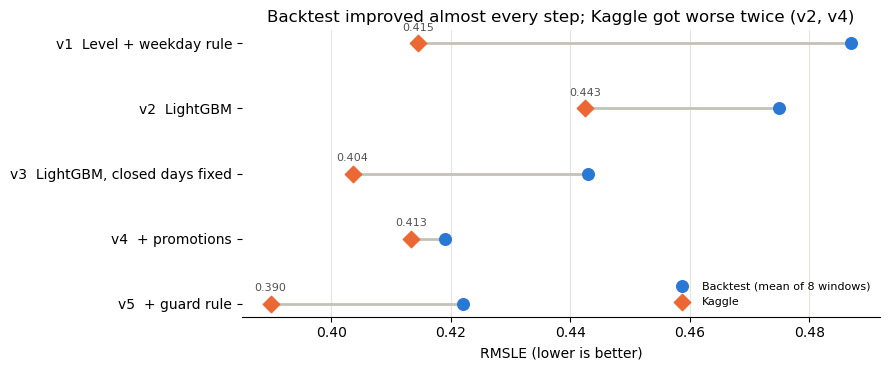

In [2]:
BACKTEST, KAGGLE = "#2a78d6", "#eb6834"  # two fixed series colors, the same in every chart

fig, ax = plt.subplots(figsize=(9, 3.8))
rows = range(len(submissions))[::-1]  # v1 at the top
for y, (name, row) in zip(rows, submissions.iterrows()):
    ax.plot([row["backtest"], row["kaggle"]], [y, y], color="#c3c2b7", linewidth=2, zorder=1)
ax.scatter(submissions["backtest"], list(rows), s=70, color=BACKTEST, label="Backtest (mean of 8 windows)", zorder=2)
ax.scatter(submissions["kaggle"], list(rows), s=70, color=KAGGLE, marker="D", label="Kaggle", zorder=2)
for y, (name, row) in zip(rows, submissions.iterrows()):
    ax.annotate(f"{row['kaggle']:.3f}", (row["kaggle"], y), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color="#52514e")

ax.set_yticks(list(rows), [f"{name}  {row['method']}" for name, row in submissions.iterrows()])
ax.set_xlabel("RMSLE (lower is better)")
ax.set_title("Backtest improved almost every step; Kaggle got worse twice (v2, v4)")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/journey.png", dpi=120)
plt.show()

**How to read it:** each row is a submission, blue is what the backtest promised, orange what Kaggle measured.

- **The backtest improved at every step except the last** (0.487 → 0.419; the guard cost 0.003 on purpose, notebook 09).
- **Kaggle went the wrong way twice: v2 and v4.** Each time the backtest said "better" and Kaggle said "worse".
- **Kaggle scores are lower than the backtest** throughout. The test period is a calm one, like the June and July windows,
  while the backtest includes the hard April windows (store 52's opening). What matters is the **direction** of a change,
  not the exact number: a backtest gives a range, not a prediction of the score.
- **Overall: 0.41457 → 0.38988**, about 6% better than the best simple rule.

That last number is a useful reality check: a carefully built model beat a two-line rule by 6%. The rule (notebook 03)
was a strong baseline, and building it first is what made every later number meaningful.

## 2. What worked

| What | Why it mattered | Where |
|---|---|---|
| **Baselines first** | Gave every later model something honest to beat. Without v1 we'd never have noticed v2 was broken. | 02, 03 |
| **Backtesting on 8 windows** | One window picked the wrong rule; windows differ more than methods do. Compare window by window. | 03 |
| **The 16-day rule** (every lag 16+ days old) | One feature table for all 16 days, and leakage impossible by construction, protected by a test. | 05 |
| **Early stopping without peeking** | The number of trees was chosen on the 16 days *before* each cutoff, never on the period being scored. | 06 |
| **Closed days = unknown, not zero** | The biggest single gain (backtest 0.475 → 0.443, Kaggle 0.443 → 0.404). | 07 |
| **Promotions** | Known in advance, better in all 8 windows. | 08 |
| **Unit tests with a planted bug** | A test that never failed proves nothing. Each leakage test was broken on purpose once. | 05, 08 |

## 3. What didn't work, and why that's fine

| What | Result | Lesson |
|---|---|---|
| Store type and cluster | Mean changed < 0.001, 4 of 8 windows better | `store_nbr` already says it all. Half the windows = noise. |
| Oil price (16+ days old) | Same: 4 of 8 windows, newest window worse | Price barely moved after 2015; nothing to learn. |
| Dropping the earthquake weeks | 0.4745 vs 0.4754 | Not every unusual period needs special handling. |
| Our first explanation of v2 (`lag_364`) | Wrong: an experiment ruled it out | A hypothesis that fits the dates perfectly still needs a test. |

Leaving features out is a result, not a failure: each one we didn't add is code we don't have to maintain.

## 4. The two disagreements: one pattern

| | v2 (notebook 07) | v4 (notebook 09) |
|---|---|---|
| **Symptom** | Backtest better, Kaggle worse | Backtest better, Kaggle worse |
| **Concentrated in** | 2 stores (18, 25) | 162 rows: 3 families, 1 day |
| **Cause** | Training targets of 0 on closed days, taught as "this store sells nothing in August" | A promotion situation never seen in training; trees can't extrapolate |
| **Why the backtest missed it** | No window reached mid-August | No window had such a promotion day |
| **How we found it** | Compared with v1, looked for where the difference concentrates | Compared with v3, same |
| **Fix** | Closed days unknown in features and targets | A guard rule decided from training data only |

**What they have in common: the backtest can only catch problems that its windows contain.** Both times the problem was
in the test period's own calendar or inputs. More windows wouldn't have helped; looking at the test inputs did.

**The checklist that worked both times:**
1. Don't tune. A worse score is information, not a target.
2. Compare with a submission you trust, row by row.
3. Look for **concentration**: a few stores, families or days usually carry most of the difference.
4. Form a hypothesis and test it with an experiment (or, at most, **one** diagnostic submission).
5. Fix the cause with a rule that could have been written without the leaderboard.

## 5. What we'd try next

Ordered by how much we expect, each with the evidence for it:

1. **Fresher features for the first days ("approach B").** Every feature is 16+ days old, which costs about 0.04
   in the backtest (notebook 05), and the simple rule still beats the model on day 1 (notebook 06). One model per
   forecast day, each using data up to the day before its horizon, would use all recent information.
   Cost: 16 models instead of 1, and a more complex leakage test.
2. **New stores.** Store 52 opened in April 2017 and made the April windows the hardest in the backtest. A rule like "for a series younger
   than 16 days, use similar stores" would help the next time a store opens.
3. **More stable early stopping.** The number of trees jumped between 279 and 2,998 across windows (notebook 09).
   Averaging it over several inner windows, or several seeds, would make results less noisy and easier to compare.
4. **A guard check for every input, not just promotions.** Before each submission, compare test inputs with training
   inputs in combinations that matter. Notebook 09 did this by hand for one feature.

Things we'd **not** try: tuning LightGBM's parameters on the leaderboard, or stacking many models for a 0.002 gain.
With windows ranging from 0.37 to 0.60, small gains can't be told apart from noise.

## 6. Habits to take to the next project

- **Ask "when would we know it?" for every column.** A value in the file isn't necessarily known at forecast time (oil).
- **Validate the way the model will be used**: in time order, the same horizon, several windows.
- **Build the simplest honest baseline first**, and keep it as a submission.
- **Treat "unknown" and "zero" differently.** Missing days, closed stores and not-yet-open stores are not zero sales.
- **Compare window by window, not just the mean**, and distrust any gain that wins only half the windows.
- **Put reused code in `src/` with tests**, and plant a bug once to prove each test can fail.
- **When validation and reality disagree, investigate before you tune.**
- **Check the test inputs against the training inputs** before the leaderboard does it for you.
- **Write down what was decided with the leaderboard's help** (the v5 guard), so the score is read honestly.